In [1]:
import os, time, copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)


if torch.cuda.is_available():
	device = torch.device('cuda')
else:
	device=torch.device('cpu')

print(torch.__version__)
print(device)

2.13.0+cu130
cuda


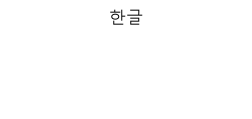

In [2]:
# 한글 글자체 가져오기
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(3, 1))
plt.title('한글')
plt.axis('off')
plt.show()

In [3]:
PATH = './data/helmet'
IMG_DIR = os.path.join(PATH, 'images')
XML_DIR = os.path.join(PATH, 'annotations')

xml_files = sorted(os.path.join(XML_DIR, x) for x in os.listdir(XML_DIR) if x.endswith('.xml'))

print(len(xml_files))
print(xml_files[0])

5000
./data/helmet\annotations\hard_hat_workers0.xml


In [4]:
import xml.etree.ElementTree as ET

def extract_info_from_xml(xml_file):
	tree = ET.parse(xml_file)
	root = tree.getroot()

	filename = root.find('filename').text
	for boxes in root.iter('object'):
		label = boxes.find('name').text
		if label == 'head' or label == 'person':
			return filename, 0
		return filename, 1

In [5]:
import cv2

img_data, label_data = [], []

t0 = time.time()
for xml_file in xml_files:
	filename, label = extract_info_from_xml(xml_file)

	img = cv2.imread(os.path.join(IMG_DIR, filename))
	if img is None:
		continue

	img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	img_data.append(cv2.resize(img, (224, 224)))
	label_data.append(label)

img_data = np.array(img_data, dtype = np.uint8)
label_data = np.array(label_data, dtype = np.int64)

print(time.time())
print(img_data.shape, img_data.dtype, img_data.nbytes)
print(label_data.shape)


1788413681.7295668
(5000, 224, 224, 3) uint8 752640000
(5000,)


In [6]:
from collections import Counter

counter = Counter(label_data.tolist())
n_unsafe, n_safe = counter[0], counter[1]
print(f'0 위험: {n_unsafe:5d} {n_unsafe / len(label_data) * 100:.1f}')
print(f'1 안전: {n_safe:5d} {n_safe / len(label_data) * 100:.1f}')
print(f'불균형 비율: {max(n_unsafe, n_safe) / min(n_unsafe, n_safe):.2f}')

0 위험:   442 8.8
1 안전:  4558 91.2
불균형 비율: 10.31


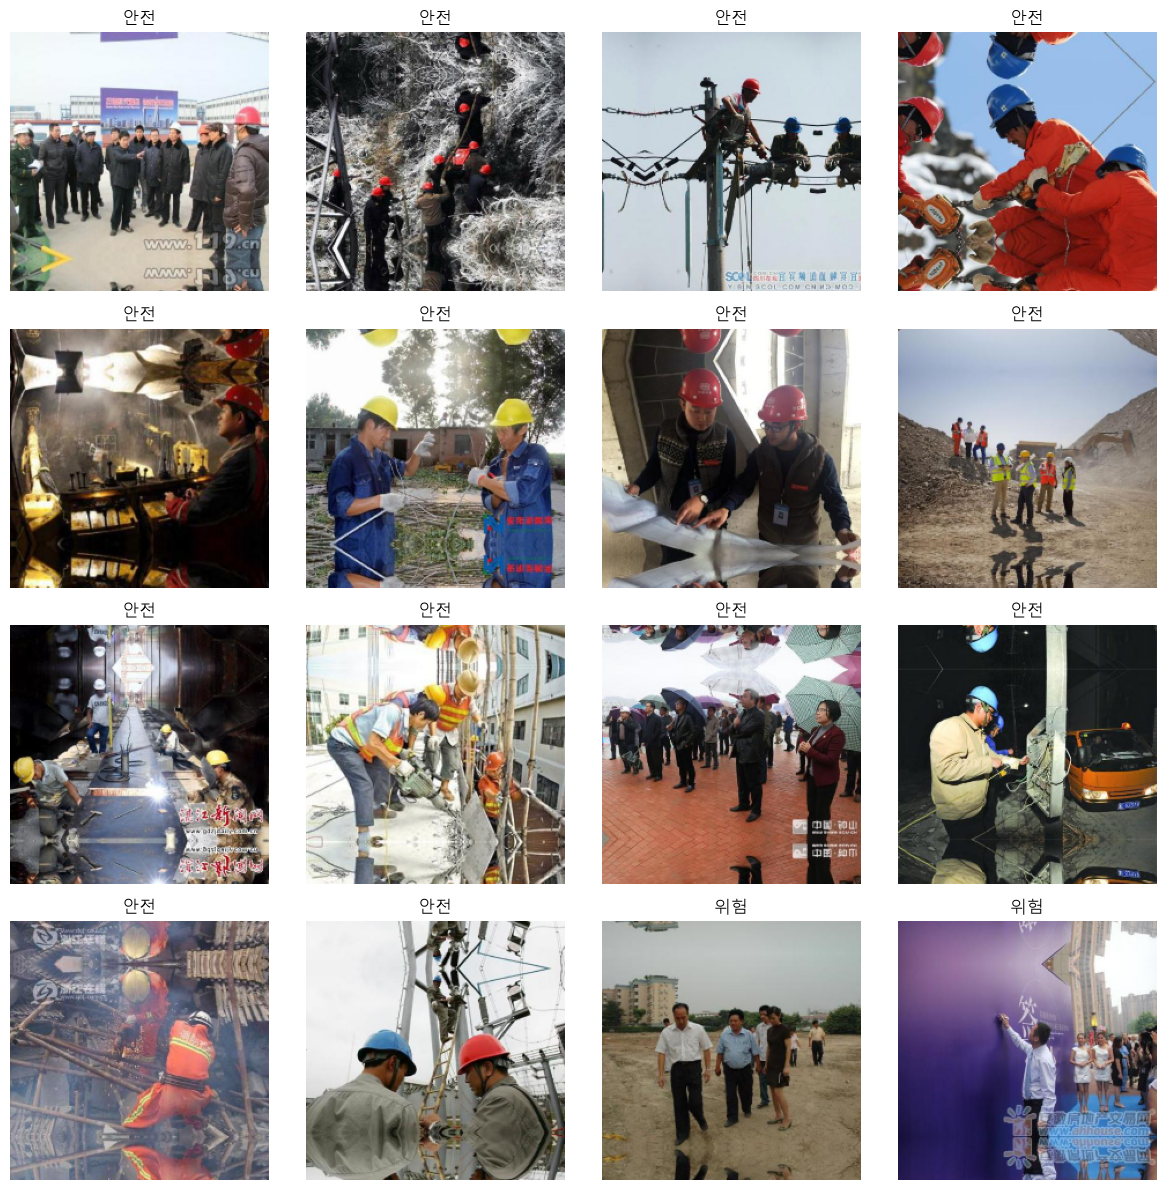

In [7]:
labels_to_names = {0: '위험', 1: '안전'}

plt.figure(figsize = (12, 12))
for i in range(16):
	plt.subplot(4, 4, i + 1)
	plt.imshow(img_data[i])
	plt.title(labels_to_names[label_data[i]])
	plt.axis('off')
plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

x_trainval, x_test, y_trainval, y_test = train_test_split(img_data,
														  label_data,
														  test_size = 0.1,
														  stratify = label_data,
														  random_state = 42)

x_train, x_val, y_train, y_val = train_test_split(x_trainval,
												  y_trainval,
												  test_size = 0.2,
												  stratify = y_trainval,
												  random_state = 42)

print(f'훈련: {len(x_train)}, 검증: {len(x_val)}, 테스트: {len(x_test)}')

훈련: 3600, 검증: 900, 테스트: 500


In [9]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406],
						 dtype = np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225],
						dtype = np.float32)

class HelmetDataset(Dataset):
	def __init__(self, images, labels, normalize = 'simple'):
		self.images = images
		self.labels = labels
		self.normalize = normalize

	def __len__(self):
		return len(self.images)

	def __getitem__(self, idx):
		img = self.images[idx].astype(np.float32) / 255.0

		if self.normalize == 'imagenet':
			img = (img - IMAGENET_MEAN) / IMAGENET_STD

		img = np.transpose(img, (2, 0, 1))

		return torch.from_numpy(img), torch.tensor(self.labels[idx], dtype = torch.float32)

def make_loaders(normalize = 'simple', batch_size = 32):
	tr = DataLoader(HelmetDataset(x_train, y_train, normalize),
					batch_size = batch_size,
					shuffle = True)
	va = DataLoader(HelmetDataset(x_val, y_val, normalize),
					batch_size = batch_size,
					shuffle = False)
	te = DataLoader(HelmetDataset(x_test, y_test, normalize),
					batch_size = batch_size,
					shuffle = False)
	return tr, va, te

_tr, _, _ = make_loaders()
xb, yb = next(iter(_tr))
print(f'입력 배치: {tuple(xb.shape)} {xb.type}')    
print(f'라벨 배치: {tuple(yb.shape)} {yb.type}')   
print(f'범위: {xb.min():.3f} ~  {xb.max():.3f}')   

입력 배치: (32, 3, 224, 224) <built-in method type of Tensor object at 0x000001D8EAA9CF50>
라벨 배치: (32,) <built-in method type of Tensor object at 0x000001D8EAA9CFF0>
범위: 0.000 ~  1.000


In [10]:
def conv_block(in_ch, out_ch):
	return [
		nn.Conv2d(in_ch, out_ch, kernel_size = 3),
		nn.ReLU(inplace = True),
		nn.BatchNorm2d(out_ch)
	]
class BaseCNN(nn.Module):
	def __init__(self):
		super().__init__()
		self.features = nn.Sequential(
			*conv_block(3, 64), *conv_block(64, 64), nn.MaxPool2d(2),
			*conv_block(64, 128), *conv_block(128, 128), nn.MaxPool2d(2),
			*conv_block(128, 256), *conv_block(256, 256), nn.MaxPool2d(2),
			*conv_block(256, 512), *conv_block(512, 512), nn.MaxPool2d(2),
		)
		self.classifier = nn.Sequential(
			nn.Flatten(),
			nn.Dropout(0.5),
			nn.Linear(512 * 10 * 10, 1024),
			nn.ReLU(inplace = True),
			nn.Dropout(0.5),
			nn.Linear(1024, 1)
		)

	def forward(self, x):
		return self.classifier(self.features(x))

def summarize(model, name = 'model'):
	total = sum(p.numel() for p in model.parameters())
	trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
	with torch.no_grad():
		out = model(torch.zeros(1, 3, 224, 224))
	print(name)
	print(f'출력 모양: {tuple(out.shape)}')
	print(f'전체 파라미터: {total:,}')
	print(f'학습 파라미터: {trainable:,}')
	print(f'고정 파라미터: {total - trainable:,}')

base_model = BaseCNN()
summarize(base_model, 'BaseCNN')

BaseCNN
출력 모양: (1, 1)
전체 파라미터: 57,120,065
학습 파라미터: 57,120,065
고정 파라미터: 0


In [11]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, confusion_matrix

#torch.no_grad()
def evaluate(model,
			 loader,
			 criterion = None):
	model.eval()
	losses, probs, trues =  [], [], []

	for xb, yb in loader:
		xb, yb = xb.to(device), yb.to(device)
		logits = model(xb).squeeze(1)

		if criterion is not None:
			losses.append(criterion(logits, yb).item() * len(yb))

		probs.append(torch.sigmoid(logits).detach().cpu().numpy())
		trues.append(yb.cpu().numpy())

	probs = np.concatenate(probs)
	trues = np.concatenate(trues)
	preds = (probs > 0.5).astype(int)

	return {
		'loss' : (sum(losses)) / len(trues) if criterion is not None else None,
		'accuracy' : accuracy_score(trues, preds),
		'recall' : recall_score(trues, preds, zero_division = 0),
		'precision' : precision_score(trues, preds, zero_division = 0),
		'auc' : roc_auc_score(trues, probs) if len(set(trues)) > 1 else float('nan'),
		'probs' : probs,
		'trues': trues,
		'preds' : preds
	}

def train_model(model,
				train_loader,
				val_loader,
				epochs = 20,
				lr = 1e-3,
				pos_weight = None,
				ckpt_path = 'best_model.pt',
				label = 'model'):
	model = model.to(device)
	pw = (None if pos_weight is None
		  else torch.tensor([pos_weight], dtype = torch.float32, device = device))
	criterion = nn.BCEWithLogitsLoss(pos_weight = pw)
	optimizer = torch.optim.Adam(model.parameters(), lr = lr)

	history = {k: [] for k in ['loss', 'val_loss', 'accuracy', 'val_accuracy', 'val_recall', 'val_precision', 'val_auc']}
	best_auc = -1.0

	for epoch in range(1, epochs + 1):
		model.train()
		run_loss, run_correct, n = 0.0, 0, 0
		t0 = time.time()

		for xb, yb in train_loader:
			xb, yb = xb.to(device), yb.to(device)
			optimizer.zero_grad()
			logits = model(xb.squeeze(1))
			logits = logits.squeeze(1)
			loss = criterion(logits, yb)
			loss.backward()
			optimizer.step()

			run_loss += loss.item() * len(yb)
			run_correct += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
			n += len(yb)
		train_loss, tr_acc = run_loss / n, run_correct / n

		m = evaluate(model, val_loader, criterion)

		history['loss'].append(train_loss)
		history['accuracy'].append(tr_acc)
		history['val_loss'].append(m['loss'])
		history['val_accuracy'].append(m['accuracy'])
		history['val_recall'].append(m['recall'])
		history['val_precision'].append(m['precision'])
		history['val_auc'].append(m['auc'])

		star = ''
		if m['auc'] > best_auc:
			best_auc = m['auc']
			torch.save(model.state_dict(), ckpt_path)
			star = '저장'

		print(f'[{label}] {epoch:2d} / {epochs}'
			  f'loss {train_loss:4f} val_loss {m['loss']:4f}'
			  f'val_acc {m['accuracy']:4f} val_auc {m['auc']:4f}'
			  f'({time.time() -t0:.0f}) {star}') 
	print(f'best val_auc = {best_auc:4f} {ckpt_path}')
	return history

In [12]:
def plot_history(history, title):
    plt.figure(figsize = (6, 4))
    plt.plot(history['loss'], label = 'train')
    plt.plot(history['val_loss'], label = 'val')
    plt.title(title)
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(loc = 'upper left')
    plt.grid(alpha = 0.3)
    plt.tight_layout()
    plt.show()

def plot_confusion(model,
                   loader,
                   ckpt_path = None,
                   title = '혼동행렬'):
    import seaborn as sns

    if ckpt_path is not None:
        model.load_state_dict(torch.load(ckpt_path, map_location = device))
    model = model.to(device)

    m = evaluate(model, loader)
    cm = confusion_matrix(m['trues'], m['preds'])

    plt.figure(figsize = (6, 5))
    sns.heatmap(cm,
                annot = True,
                fmt = 'd',
                cmap = 'Blues',
                annot_kws = {'size' : 16},
                xticklabels = ['위험', '안전'],
                yticklabels = ['위험', '안전'])
    plt.xlabel('예측값')
    plt.ylabel('실제값')
    plt.title(title)
    plt.tight_layout()
    plt.show()
    print(f'정확도: {m['accuracy']:.4f} 재현율: {m['recall']:.4f}'
          f'정밀도: {m['precision']:.4f} AUC: {m['auc']:.4f}')
    return m

In [13]:
print("설정 device:", device)
print("모델 device:", next(base_model.parameters()).device)
print("GPU 이름:", torch.cuda.get_device_name(0))

설정 device: cuda
모델 device: cpu
GPU 이름: NVIDIA GeForce RTX 5060 Laptop GPU


In [14]:
EPOCHS = 2

train_loader, val_loader, test_loader = make_loaders(normalize = 'simple',
                                                     batch_size = 32)
base_model = BaseCNN().to(device)
base_history = train_model(base_model,
                           train_loader,
                           val_loader,
                           epochs = EPOCHS,
                           lr = 1e-3,
                           ckpt_path = 'best_base_model.pt',
                           label = 'base')

[base]  1 / 2loss 3.640138 val_loss 0.449364val_acc 0.894444 val_auc 0.673537(41) 저장
[base]  2 / 2loss 1.339693 val_loss 0.958404val_acc 0.847778 val_auc 0.753460(47) 저장
best val_auc = 0.753460 best_base_model.pt


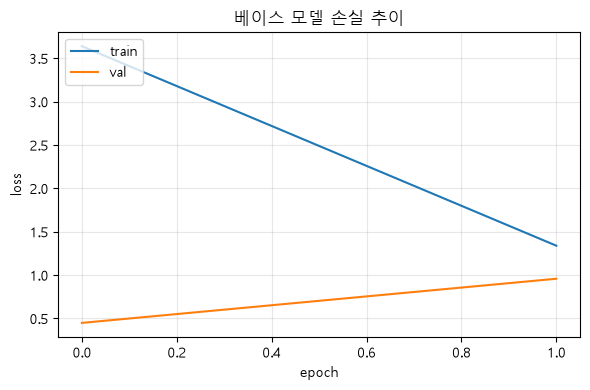

In [15]:
plot_history(base_history, '베이스 모델 손실 추이')

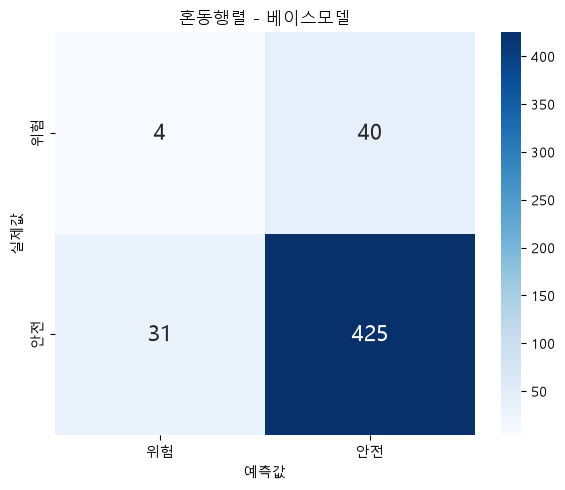

정확도: 0.8580 재현율: 0.9320정밀도: 0.9140 AUC: 0.7418


In [16]:
base_metrics = plot_confusion(BaseCNN(), test_loader,
                              ckpt_path ='best_base_model.pt',
                              title = '혼동행렬 - 베이스모델')

In [19]:
from torchvision import models

class TransferModel(nn.Module):
    def __init__(self, freeze = True):
        super().__init__()
        weights = models.EfficientNet_V2_S_Weights.IMAGENET1K_V1
        backbone = models.efficientnet_v2_s(weights = weights)

        self.features = backbone.features

        if freeze:
            for p in self.features.parameters():
                p.requires_grad = False
                
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(1280, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.fc(self.dropout(x))

transfer_model = TransferModel(freeze = True)
summarize(transfer_model, 'TransferModel (EfficeintNetV2-S 고정)')

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to C:\Users\KDS-30/.cache\torch\hub\checkpoints\efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:01<00:00, 83.4MB/s]


TransferModel (EfficeintNetV2-S 고정)
출력 모양: (1, 1)
전체 파라미터: 20,178,769
학습 파라미터: 1,281
고정 파라미터: 20,177,488


In [20]:
tr_loader, va_loader, te_loader = make_loaders(normalize = 'imagenet',
                                               batch_size = 32)
xb, _ = next(iter(tr_loader))
print(f'정규화범위: {xb.min():.3f} ~ {xb.max():.3f}')

정규화범위: -2.118 ~ 2.640


In [21]:
transfer_model = TransferModel(freeze = True)
transfer_history = train_model(transfer_model,
                               tr_loader,
                               va_loader,
                               epochs = EPOCHS,
                               lr = 5e-4,
                               ckpt_path = 'best_transfer_model.pt',
                               label = '전이학습')

[전이학습]  1 / 2loss 0.352477 val_loss 0.311828val_acc 0.908889 val_auc 0.684314(31) 저장
[전이학습]  2 / 2loss 0.267308 val_loss 0.279922val_acc 0.908889 val_auc 0.795183(30) 저장
best val_auc = 0.795183 best_transfer_model.pt


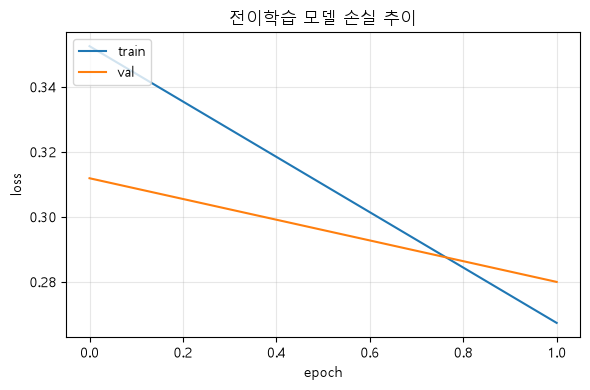

In [22]:
plot_history(transfer_history, '전이학습 모델 손실 추이' )

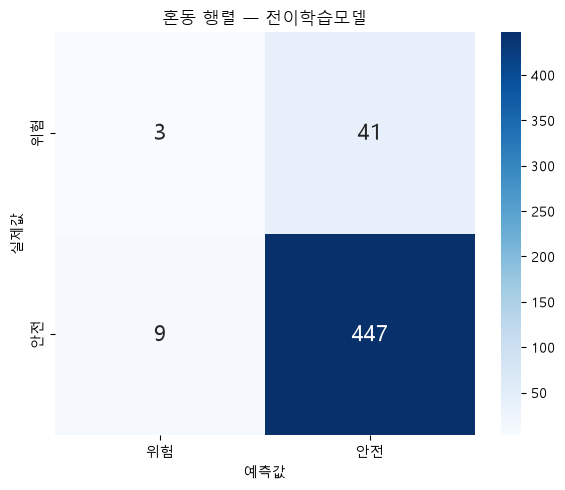

정확도: 0.9000 재현율: 0.9803정밀도: 0.9160 AUC: 0.8238


In [24]:
transfer_metrics = plot_confusion(TransferModel(freeze = True), te_loader, ckpt_path = "best_transfer_model.pt", title = "혼동 행렬 ㅡ 전이학습모델")

In [25]:
# 클래스 가중치 적용 (class_weight)

labels_int = np.asarray(label_data).astype(np.int64)
unsafe, safe = np.bincount(labels_int)
total = unsafe + safe

weight_for_unsafe = (1 / unsafe) * (total / 2.0)
weight_for_safe = (1 / safe) * (total / 2.0)

# 텐서로 만들때 dtype = torch.float32
pos_weight = weight_for_safe / weight_for_unsafe
print(pos_weight)

if pos_weight < 1:
    print("안전쪽에 벌점을 낮춘다.")

else:
    print("안전쪽에 벌점을 높인다.")

0.09697235629662132
안전쪽에 벌점을 낮춘다.


In [26]:
weighted_model = TransferModel(freeze = True)
weighted_history = train_model(
    weighted_model, tr_loader, va_loader, epochs = EPOCHS, lr = 5e-4, pos_weight = pos_weight,
    ckpt_path = "best_weighted_model.pt", label = "가중치적용"
)

[가중치적용]  1 / 2loss 0.104844 val_loss 0.090777val_acc 0.842222 val_auc 0.910076(41) 저장
[가중치적용]  2 / 2loss 0.081235 val_loss 0.076626val_acc 0.834444 val_auc 0.925747(41) 저장
best val_auc = 0.925747 best_weighted_model.pt


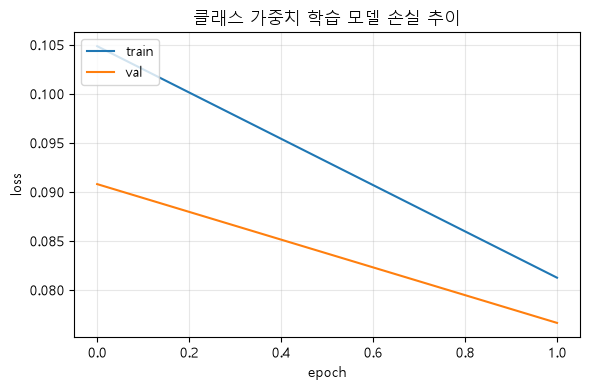

In [27]:
plot_history(weighted_history, "클래스 가중치 학습 모델 손실 추이")

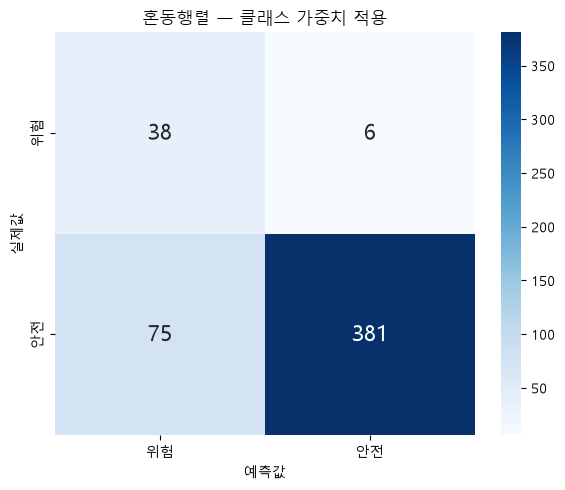

정확도: 0.8380 재현율: 0.8355정밀도: 0.9845 AUC: 0.9154


In [28]:
weighted_metrics = plot_confusion(TransferModel(freeze = True), te_loader, ckpt_path = "best_weighted_model.pt",
                                  title = "혼동행렬 ㅡ 클래스 가중치 적용")